## Домашка 3

#### *«Ты понимаешь, что это значит? Это значит, что эта пакость не работает!» — Назад в будущее*

Эта домашка про метрики в a/b-тестировании. За неё можно получить максимум 12 баллов.

**Дедлайны**  
Мягкий дедлайн: 04.10.2026 23:59 по МСК.   
Жесткий дедлайн: 11.10.2026 23:59 по МСК.  

Штраф за сдачу после мягкого дедлайна: –20% от набранного балла.   
После жесткого дедлайна работы не принимаются.   

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета.
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_3). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3.

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_3_data.zip)

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import norm, pearsonr
import math

### Warm up

#### 1. Сопоставьте тип эксперимента с продуктовым изменением — 2 балла

a) По-юзерный A/B тест  
b) Свитчбек (по времени)   
c) Региональный A/B тест


1. Новая логика выдачи контента на главной в стриминговом сервисе фильмов и сериалов.
2. Запуск динамического ценообразования в сервисе доставки еды.
3. Тестирование push-уведомления о брошенной корзине в e-commerce приложении.
4. Раскатка в сервисе такси через эксперимент новой схемы комиссий для водителей (старт с одного города).
5. Добавление ипотечного калькулятора с точкой входа в Новостройки на главной сервиса объявлений Недвижимости.
6. Изменение SLA времени доставки в сервисе курьерской доставки (старт с одного города).

1. a
2. b
3. a
4. c
5. a
6. c

In [ ]:
# your answer is here

### Case Study. Дизайн эксперимента в сервисе объявлений жилой недвижимости 🏡

**Легенда**  
Вы работаете продуктовым аналитиком в сервисе объявлений жилой недвижимости. Платформа позволяет пользователям размещать объявления о продаже и аренде жилья (как частным лицам, так и застройщикам), а другим — просматривать и контактировать / оставлять заявки по объявлениям.    
Ваша команда "Новостройки" хочет разместить на главной ипотечный калькулятор с точкой входа напрямую в свой раздел. Цель — увеличить число заявок.

**Гипотеза** — размещение ипотечного калькулятора на главной сервиса увеличит долю пользователей, оставивших заявку в Новостройках, как минимум на 15%, при этом не ухудшит аналогичные метрики в других разделах (Аренда, Вторичка) более чем на 3%.

$$
\Delta_{\mathrm{rel}}=\left(\frac{p_t-p_c}{p_c}\right)\times 100\% \quad \text{(формула эффекта)}
$$

**Ограничения** — вы не можете держать главную в тесте больше 14 дней из-за запланированного календаря экспериментов с другими командами.

**Набор метрик для дизайна.**   
Target — доля пользователей с заполненной заявкой на звонок (Новостройки).   

Guardrails:
- доля пользователей с контактом по объявлению Аренды;
- доля пользователей с контактом по объявлению Вторички;
- доля пользователей с контактом по объявлению из любой категории (подумайте, зачем нужна эта метрика? от какой ловушки она защищает?).   

Informative:
- доля пользователей, перешедших с главной в раздел Аренды;
- доля пользователей, перешедших с главной в раздел Вторички;
- доля пользователей, перешедших с главной в раздел Новостроек;
- доля пользователей с переходами в список объявлений по навигации на главной.

Все доли рассчитываются от набранного объема пользователей в каждой из групп. Пользователи попадают в exposure сразу при посещении главной.

**Для расчетов метрик используйте следующие ивенты:**
- Для target и guardrails — contact_submit.
- Для informative — list_view и source==main_nav.

*В рамках такого эксперимента также имеет смысл смотреть на среднее число контактов / заявок по каждому из разделов и в общем, а не просто на бинарные метрики. Но в данном задании мы сосредоточимся на долях, чтобы не раздувать алгоритм расчета до полного реалистичного пресета метрик.*

In [8]:
df_logs = pd.read_csv('data/hw_3_events_data.csv')
df_logs.head()

,timestamp,user_id,session_id,event,category,source,listing_id
0,2025-06-01 00:00:00,114227,8828585581,main_view,none,none,NaN
1,2025-06-01 00:00:00,212987,8591655166,main_view,none,none,NaN
2,2025-06-01 00:00:00,1413962,2533393268,add_fav,rent_long,other,992874562.0
3,2025-06-01 00:00:00,1221850,2060698550,main_view,none,none,NaN
4,2025-06-01 00:00:00,31469,6550065912,main_view,none,none,NaN


In [9]:
df_exps = pd.read_csv('data/hw_3_experimens_history.csv')
df_exps.head()

,exp_id,days,target_contact_effect_rel,target_contact_p_value,target_contact_p0,target_contact_effect_abs,proxy_card_effect_rel,proxy_card_p_value,proxy_card_p0,proxy_card_effect_abs,proxy_fav_effect_rel,proxy_fav_p_value,proxy_fav_p0,proxy_fav_effect_abs,proxy_form_effect_rel,proxy_form_p_value,proxy_form_p0,proxy_form_effect_abs
0,3937,7,0.000067,0.448527,0.000382,2.562909e-08,0.000814,0.254909,0.014527,0.000012,0.014880,0.443100,0.004335,0.000065,0.054000,0.200074,0.000782,0.000042
1,2806,7,0.000053,0.353007,0.000339,1.793707e-08,0.025588,0.002390,0.012604,0.000323,0.055000,0.007806,0.004289,0.000236,0.042542,0.077772,0.000687,0.000029
2,3457,7,0.000036,0.397718,0.000353,1.255839e-08,0.010437,0.171633,0.013020,0.000136,0.007892,0.486577,0.004187,0.000033,0.028638,0.385118,0.000718,0.000021
3,1002,7,0.000032,0.266510,0.000388,1.246465e-08,0.015525,0.001215,0.012697,0.000197,0.045051,0.000516,0.004062,0.000183,0.025849,0.164273,0.000735,0.000019
4,9070,7,0.000046,0.461855,0.000377,1.722521e-08,0.011572,0.217843,0.013902,0.000161,0.010127,0.317622,0.004349,0.000044,0.036751,0.236595,0.000786,0.000029


Описание данных hw_3_events_data:

- timestamp — дата-время взаимодействия с контентом
- user_id — уникальный идентификатор пользователя
- session_id – уникальный идентификатор сессии
- event — тип события
- category — категория, в которой произошло событие (не приходит для главной)
- source — источник перехода на страницу
- listing_id – уникальный идентификатор объявления

Описание данных hw_3_experimens_history (это история экспериментов именно в разделе Новостройки):

- exp_id — уникальный идентификатор эксперимента
- days — длительность теста
- target_contact_effect_rel — относительный эффект на таргет метрике
- target_contact_p_value — p-value полученного результата для таргет метрики
- target_contact_p0 — значение конверсии таргет метрики в контроле
- target_contact_effect_abs — абсолютный эффект на таргет метрике
- proxy_card_effect_rel — относительный эффект на конверсии просмотра карточки объявления
- proxy_card_p_value — p-value полученного результата для конверсии просмотра карточки объявления
- proxy_card_p0 — значение конверсии просмотра карточки объявления в контроле
- proxy_card_effect_abs — абсолютный эффект на конверсии просмотра карточки объявления
- proxy_fav_effect_rel — относительный эффект на конверсии добавления объявления в избранное
- proxy_fav_p_value — p-value полученного результата для конверсии добавления объявления в избранное
- proxy_fav_p0 — значение конверсии добавления объявления в избранное в контроле
- proxy_fav_effect_abs – абсолютный эффект на конверсии добавления объявления в избранное
- proxy_form_effect_rel — относительный эффект на конверсии открытия формы заявки на звонок по объявлению
- proxy_form_p_value — p-value полученного результата для конверсии открытия формы заявки на звонок по объявлению
- proxy_form_p0 — значение конверсии открытия формы заявки на звонок по объявлению в контроле
- proxy_form_effect_abs — абсолютный эффект на конверсии открытия формы заявки на звонок по объявлению

#### 2. Рассчитайте количество дней, необходимое для детектирования заявленных в гипотезе эффектов (target и guardrails-метрики) — 2 балла
Здесь и далее используйте для расчетов значение alpha = 0.01 (делаем поправку на принятие решения по набору метрик) и beta = 0.2. А также двусторонний критерий — мы заранее не знаем, куда двинутся метрики, поэтому хотим учесть и противоположные эффекты.  

Для метрики "доля пользователей с контактом по объявлению из любой категории" также используйте эффект в 3%.

In [10]:
df_logs['date'] = pd.to_datetime(df_logs['timestamp']).dt.date

In [11]:
alpha = 0.01
beta = 0.2

In [12]:
def sample_size(p, mde):
    p2 = p * (1 + mde)
    z = norm.ppf(1 - alpha / 2) + norm.ppf(1 - beta)
    return math.ceil(z ** 2 * (p * (1 - p) + p2 * (1 - p2)) / (p2 - p) ** 2)

In [13]:
first_day = df_logs[df_logs['event'] == 'main_view'].groupby('user_id')['date'].min()
contacts = df_logs[df_logs['event'] == 'contact_submit']

In [14]:
metrics = {
    'newbuilds': (['newbuilds'], 0.15),
    'rent': (['rent_long', 'rent_daily'], 0.03),
    'secondary': (['secondary'], 0.03),
    'any': (['newbuilds', 'rent_long', 'rent_daily', 'secondary'], 0.03)
}

In [15]:
result = []
for name, (cats, mde) in metrics.items():
    metric_contacts = contacts[contacts['category'].isin(cats)]
    days_needed = None
    for i, d in enumerate(sorted(first_day.unique())):
        users = first_day[first_day <= d].index
        conv_users = metric_contacts[(metric_contacts['date'] <= d) & (metric_contacts['user_id'].isin(users))]['user_id'].nunique()
        p = conv_users / len(users)
        n = sample_size(p, mde)
        if 2 * n <= len(users):
            days_needed = i + 1
            break
    result.append([name, mde, round(p, 5), n, len(users), days_needed])

pd.DataFrame(result, columns=['metric', 'mde', 'p', 'n_per_group', 'users_total', 'days'])

,metric,mde,p,n_per_group,users_total,days
0,newbuilds,0.15,0.00037,2992345,1781124,NaN
1,rent,0.03,0.03419,743759,1583062,10.0
2,secondary,0.03,0.01452,1787969,1781124,NaN
3,any,0.03,0.03875,653071,1338902,7.0


**Вывод**: за 14 дней можно задетектировать эффект только на guardrail-метриках по Аренде (10 дней) и по контактам из любой категории (7 дней). Для таргета (заявки в Новостройках) конверсия очень низкая, около 0.04%, и нужно примерно 3 млн пользователей на группу, а за 14 дней на главную приходит только 1.78 млн. Для Вторички тоже не хватает трафика: нужно около 1.79 млн на группу. Значит, в ограничение 14 дней тест по этим метрикам не укладывается.

#### 3. Рассчитайте MDE для информативных метрик — 2 балла
В реальности эффекты по информативным критериям, которые мы также хотим включать в пресет метрик, нужно сравнивать на достижимость на основе прошлых экспериментов. Как правило, проделав это упражнение один раз, вы просто сохраняете достижимый трешхолд в базе знаний команды и принимаете решение о включении их в базовый набор. Проверка эффектов для каждого теста не требуется. Однако, стоит делать периодический пересмотр зафиксированных достижимых эффектов, например раз в полгода / год, или при сильных изменениях продукта / рынка.

В данном задании мы с вами не будем опираться на историю тестов, просто потренируемся делать обратный расчет — размера эффекта от заданной длительности (14 дней).

*Для числителя используйте только ивенты с источником main_nav*

In [16]:
users_total = df_logs[df_logs['event'] == 'main_view']['user_id'].nunique()
n = users_total / 2

In [17]:
nav = df_logs[(df_logs['event'] == 'list_view') & (df_logs['source'] == 'main_nav')]

In [18]:
metrics = {
    'rent': ['rent_long', 'rent_daily'],
    'secondary': ['secondary'],
    'newbuilds': ['newbuilds'],
    'any': ['rent_long', 'rent_daily', 'secondary', 'newbuilds']
}

In [19]:
z = norm.ppf(1 - alpha / 2) + norm.ppf(1 - beta)


In [20]:
result = []
for name, cats in metrics.items():
    p = nav[nav['category'].isin(cats)]['user_id'].nunique() / users_total
    mde_abs = z * math.sqrt(2 * p * (1 - p) / n)
    result.append([name, round(p, 4), round(mde_abs, 5), round(mde_abs / p * 100, 2)])

pd.DataFrame(result, columns=['metric', 'p', 'mde_abs', 'mde_rel_%'])

,metric,p,mde_abs,mde_rel_%
0,rent,0.4151,0.00252,0.61
1,secondary,0.2240,0.00214,0.95
2,newbuilds,0.0446,0.00106,2.37
3,any,0.5459,0.00255,0.47


**Вывод**: за 14 дней (около 890 тыс. пользователей в группе) информативные метрики переходов чувствительные, потому что базовые конверсии у них высокие. Минимальный детектируемый эффект меньше 1% для переходов в Аренду, во Вторичку и для любых переходов по навигации. Для переходов в Новостройки MDE около 2.4%, так как конверсия там ниже. Все эти эффекты выглядят достижимыми, так что метрики можно оставить в пресете.

#### 4. Выбираем proxy-метрику (шаг 1) — 2 балла
Стало понятно, что за 14 дней мы не успеем замерить эффект по таргету. Что делать? Можно использовать методы снижения дисперсии, а можно попробовать подобрать proxy-метрику. Давайте реализуем второй вариант.

**Для proxy будем использовать 3-х кандидатов:**
- доля пользователей с просмотром карточки объявления в Новостройках;
- доля пользователей, добавивших в избранное объявление в Новостройках;
- доля пользователей, открывших форму заявки в Новостройках — связь с автором объявления в этом разделе предполагает обратный звонок от офиса продаж, поэтому чтобы сделать событие контакта, релевантное другим разделам, нужно ввести свой номер телефона в форму заявки, расположенную на карточке.

Для каждой из proxy-метрик:
- Рассчитайте MDE для заданной длительности — 14 дней;
- По историческому набору экспериментов постройте диаграмму рассеяния зафиксированных эффектов и длительности тестов (пометьте значимые эффекты).

**Для расчетов метрик используйте следующие ивенты:**
- Для proxy — card_view, add_fav, form_start.

In [21]:
import matplotlib.pyplot as plt

In [22]:
users_total = df_logs[df_logs['event'] == 'main_view']['user_id'].nunique()
n = users_total / 2
z = norm.ppf(1 - alpha / 2) + norm.ppf(1 - beta)

In [23]:
newbuilds = df_logs[df_logs['category'] == 'newbuilds']

In [24]:
result = []
for event in ['card_view', 'add_fav', 'form_start']:
    p = newbuilds[newbuilds['event'] == event]['user_id'].nunique() / users_total
    mde_abs = z * math.sqrt(2 * p * (1 - p) / n)
    result.append([event, round(p, 5), round(mde_abs, 6), round(mde_abs / p * 100, 2)])

pd.DataFrame(result, columns=['metric', 'p', 'mde_abs', 'mde_rel_%'])

,metric,p,mde_abs,mde_rel_%
0,card_view,0.01366,0.000595,4.35
1,add_fav,0.00396,0.000322,8.12
2,form_start,0.00072,0.000137,19.10


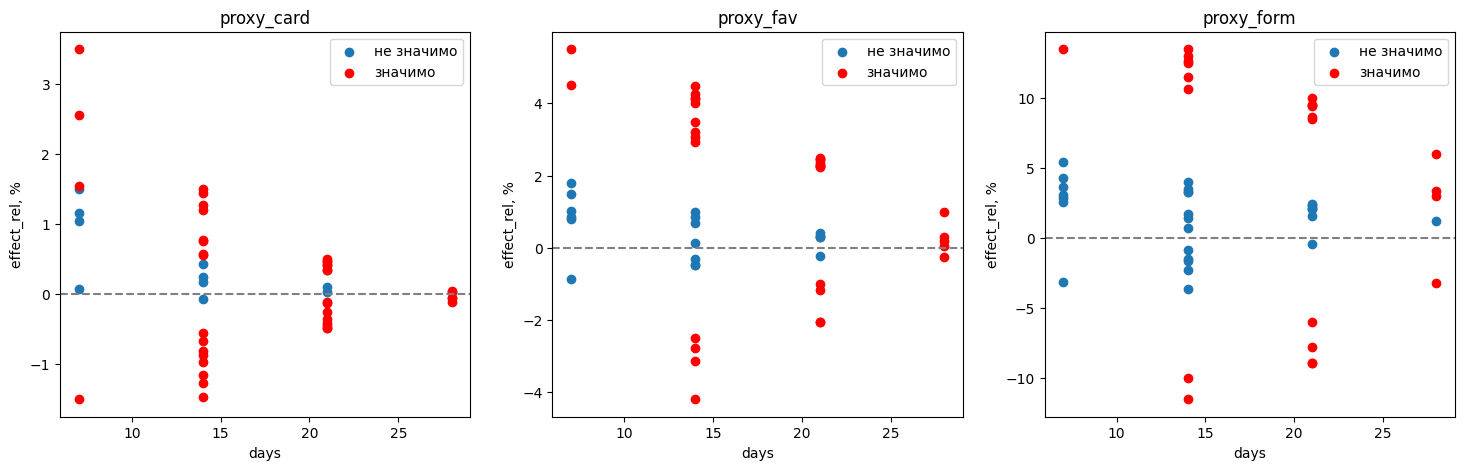

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, m in zip(axes, ['proxy_card', 'proxy_fav', 'proxy_form']):
    sig = df_exps[m + '_p_value'] < alpha
    ax.scatter(df_exps[~sig]['days'], df_exps[~sig][m + '_effect_rel'] * 100, label='не значимо')
    ax.scatter(df_exps[sig]['days'], df_exps[sig][m + '_effect_rel'] * 100, color='red', label='значимо')
    ax.axhline(0, color='grey', linestyle='--')
    ax.set_title(m)
    ax.set_xlabel('days')
    ax.set_ylabel('effect_rel, %')
    ax.legend()

plt.show()

**Вывод**: значимыми я считал эффекты с p-value < 0.01, как и в остальных расчётах. На всех трёх метриках с ростом длительности теста значимыми становятся всё меньшие эффекты, а их разброс сужается.

Если сравнить MDE на 14 дней с историческими эффектами в 14-дневных тестах, то для просмотра карточки нужен эффект 4.35%, а в истории значимые эффекты были не больше 1.5%. Для избранного нужно 8.1%, а исторически было до 4.5%. Для открытия формы нужно 19.1%, а в истории встречались эффекты до 13.5%.

Получается, что ни одна proxy-метрика с таким MDE за 14 дней не гарантирует детекцию типичных эффектов. Ближе всего к достижимости открытие формы заявки: на ней исторически самые крупные эффекты, и по смыслу она ближе всего к таргету.

#### 5. Выбираем proxy-метрику (шаг 2) — 2 балла
Для каждой из proxy-метрик по историческому набору экспериментов рассчитайте:
- Binary Sensitivity;
- MSE с таргет-метрикой;
- Корреляцию Пирсона с таргет-метрикой.

In [26]:
result = []
for m in ['proxy_card', 'proxy_fav', 'proxy_form']:
    sensitivity = (df_exps[m + '_p_value'] < alpha).mean()
    mse = ((df_exps[m + '_effect_rel'] - df_exps['target_contact_effect_rel']) ** 2).mean()
    corr, p_value = pearsonr(df_exps[m + '_effect_rel'], df_exps['target_contact_effect_rel'])
    result.append([m, sensitivity, round(mse, 5), round(corr, 3), round(p_value, 5)])

pd.DataFrame(result, columns=['metric', 'binary_sensitivity', 'mse', 'pearson_corr', 'corr_p_value'])

,metric,binary_sensitivity,mse,pearson_corr,corr_p_value
0,proxy_card,0.80,0.01430,0.150,0.29845
1,proxy_fav,0.64,0.01104,0.670,0.00000
2,proxy_form,0.46,0.00655,0.724,0.00000


**Вывод**: просмотр карточки самый чувствительный (значим в 80% тестов), но почти не связан с таргетом: корреляция 0.15 и незначима, а MSE самое большое. Открытие формы лучше всего повторяет таргет (корреляция 0.72, минимальное MSE), но чувствительность у него самая низкая, 46%. Хотя это всё равно выше, чем у самого таргета: он значим в 40% тестов. Добавление в избранное посередине: чувствительность 64% и высокая корреляция 0.67.

#### 6. Выбираем proxy-метрику (шаг 3) — 2 балла
Для каждой из proxy-метрик по историческому набору экспериментов:
- Рассчитайте Proxy Score;
- Выведите матрицу согласия-несогласия знаков с таргет-метрикой.

Выберите proxy, с которой вы пойдете в а/б тест, обоснуйте выбор.

In [27]:
def state(df, m):
    return np.where(df[m + '_p_value'] >= alpha, 'не значимо', np.where(df[m + '_effect_rel'] > 0, '+', '-'))

In [28]:
target = state(df_exps, 'target_contact')

In [29]:
result = []
for m in ['proxy_card', 'proxy_fav', 'proxy_form']:
    proxy = state(df_exps, m)
    agree = ((target != 'не значимо') & (target == proxy)).sum()
    disagree = ((target == '+') & (proxy == '-') | (target == '-') & (proxy == '+')).sum()
    score = (agree - disagree) / (target != 'не значимо').sum()
    result.append([m, agree, disagree, round(score, 3)])
    print(m)
    display(pd.crosstab(pd.Series(target, name='target'), pd.Series(proxy, name=m)))

pd.DataFrame(result, columns=['metric', 'agree', 'disagree', 'proxy_score'])

proxy_card


proxy_card,+,-,не значимо
target,,,
+,9,7,2
-,0,2,0
не значимо,11,11,8


proxy_fav


proxy_fav,+,-,не значимо
target,,,
+,15,0,3
-,0,2,0
не значимо,8,7,15


proxy_form


proxy_form,+,-,не значимо
target,,,
+,11,0,7
-,0,1,1
не значимо,5,6,19


,metric,agree,disagree,proxy_score
0,proxy_card,11,7,0.20
1,proxy_fav,17,0,0.85
2,proxy_form,12,0,0.60


**Вывод**: в тест я бы пошёл с долей пользователей, добавивших объявление в Новостройках в избранное (proxy_fav).

У неё самый высокий Proxy Score, 0.85. Из 20 тестов со значимым таргетом она поймала 17, причём всегда в ту же сторону, и ни разу не показала противоположный знак. Ещё у неё высокая корреляция с таргетом (0.67) и чувствительность 64%.

Просмотр карточки не подходит: он часто значимо двигается в противоположную сторону (7 тестов, где таргет вырос, а карточки упали), и корреляция с таргетом слабая.

Открытие формы тоже ни разу не ошиблось со знаком и сильнее коррелирует с таргетом. Но оно пропустило 8 из 20 значимых изменений таргета, а его MDE на 14 дней (19%) сильно больше, чем у избранного (8.1%).